In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")

# Find the repository root automatically.
ROOT = Path.cwd()
while not (ROOT / "data_labeling").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Repository root was not found.")
    ROOT = ROOT.parent

LABEL_FILE = (
    ROOT
    / "data_labeling"
    / "data_labels"
    / "noaa"
    / "labels_noaa_2010_2026_binary.csv"
)

assert LABEL_FILE.exists(), f"File not found: {LABEL_FILE}"

data = pd.read_csv(LABEL_FILE)
print("Labels:", LABEL_FILE)
print("Rows:", f"{len(data):,}")
data.head()

Labels: /Users/piyushluitel/Desktop/PhD/Research/Full-Disk-Attention---Continual-Learning-/data_labeling/data_labels/noaa/labels_noaa_2010_2026_binary.csv
Rows: 128,117


,label,goes_class
0,2010/12/06/HMI.m2010.12.06_07.00.00.jpg,0
1,2010/12/06/HMI.m2010.12.06_08.00.00.jpg,0
2,2010/12/06/HMI.m2010.12.06_09.00.00.jpg,0
3,2010/12/06/HMI.m2010.12.06_10.00.00.jpg,0
4,2010/12/06/HMI.m2010.12.06_11.00.00.jpg,0


In [2]:
# Extract time from paths such as HMI.m2014.05.10_08.00.00.jpg.
timestamp_text = data["label"].str.extract(
    r"HMI\.m(\d{4}\.\d{2}\.\d{2}_\d{2}\.\d{2}\.\d{2})"
)[0]

data["timestamp"] = pd.to_datetime(
    timestamp_text,
    format="%Y.%m.%d_%H.%M.%S",
    errors="coerce",
)

data["goes_class"] = pd.to_numeric(
    data["goes_class"],
    errors="coerce",
)

# Important data-quality checks.
assert data["timestamp"].notna().all()
assert data["goes_class"].isin([0, 1]).all()
assert not data["label"].duplicated().any()

data = data.sort_values("timestamp").reset_index(drop=True)

print("First image:", data["timestamp"].min())
print("Last image:", data["timestamp"].max())
print("Duplicate paths:", data["label"].duplicated().sum())
print("Missing timestamps:", data["timestamp"].isna().sum())

First image: 2010-12-06 07:00:00
Last image: 2026-07-31 23:00:00
Duplicate paths: 0
Missing timestamps: 0


In [3]:
data["year"] = data["timestamp"].dt.year

yearly = (
    data.groupby("year")["goes_class"]
    .agg(samples="size", FL="sum")
)

yearly["NF"] = yearly["samples"] - yearly["FL"]
yearly["FL_percent"] = 100 * yearly["FL"] / yearly["samples"]
yearly["NF_percent"] = 100 * yearly["NF"] / yearly["samples"]

display(yearly)

,samples,FL,NF,FL_percent,NF_percent
year,,,,,
2010,562,0,562,0.000000,100.000000
2011,6528,1235,5293,18.918505,81.081495
2012,6516,1358,5158,20.841007,79.158993
2013,7656,1415,6241,18.482236,81.517764
2014,8405,2702,5703,32.147531,67.852469
2015,8511,1663,6848,19.539420,80.460580
2016,8337,250,8087,2.998681,97.001319
2017,8377,330,8047,3.939358,96.060642
2018,8417,0,8417,0.000000,100.000000


In [4]:
# Complete stage periods before separating training and holdout.
BLOCK_LIMITS = {
    "Stage 1 complete": (
        pd.Timestamp("2010-12-06 07:00:00"),
        pd.Timestamp("2017-12-31 23:00:00"),
    ),
    "Stage 2 complete": (
        pd.Timestamp("2018-01-02 00:00:00"),
        pd.Timestamp("2023-06-29 22:00:00"),
    ),
    "Stage 3 complete": (
        pd.Timestamp("2023-07-01 00:00:00"),
        pd.Timestamp("2024-06-29 10:00:00"),
    ),
    "Validation": (
        pd.Timestamp("2024-07-01 00:00:00"),
        pd.Timestamp("2025-06-30 23:00:00"),
    ),
    "Test": (
        pd.Timestamp("2025-07-02 00:00:00"),
        pd.Timestamp("2026-07-31 23:00:00"),
    ),
}

# A complete 24-hour NF-only separation between major periods.
MAJOR_GAPS = {
    "Stage 1 → Stage 2": (
        pd.Timestamp("2018-01-01 00:00:00"),
        pd.Timestamp("2018-01-01 23:00:00"),
    ),
    "Stage 2 → Stage 3": (
        pd.Timestamp("2023-06-29 23:00:00"),
        pd.Timestamp("2023-06-30 22:00:00"),
    ),
    "Stage 3 → Validation": (
        pd.Timestamp("2024-06-29 11:00:00"),
        pd.Timestamp("2024-06-30 10:00:00"),
    ),
    "Validation → Test": (
        pd.Timestamp("2025-07-01 00:00:00"),
        pd.Timestamp("2025-07-01 23:00:00"),
    ),
}

In [5]:
gap_rows = []

for name, (start, end) in MAJOR_GAPS.items():
    gap = data[data["timestamp"].between(start, end)].copy()

    expected_hours = pd.date_range(start, end, freq="h")
    missing_hours = expected_hours.difference(gap["timestamp"])

    fl = int(gap["goes_class"].sum())
    nf = len(gap) - fl

    gap_rows.append({
        "boundary": name,
        "start": start,
        "end": end,
        "samples": len(gap),
        "FL": fl,
        "NF": nf,
        "missing_hours": len(missing_hours),
        "valid_gap": (
            len(gap) == 24
            and fl == 0
            and len(missing_hours) == 0
        ),
    })

major_gap_summary = pd.DataFrame(gap_rows)
display(major_gap_summary)

assert major_gap_summary["valid_gap"].all()
print("All major boundaries have valid 24-hour NF-only gaps.")

,boundary,start,end,samples,FL,NF,missing_hours,valid_gap
0,Stage 1 → Stage 2,2018-01-01 00:00:00,2018-01-01 23:00:00,24,0,24,0,True
1,Stage 2 → Stage 3,2023-06-29 23:00:00,2023-06-30 22:00:00,24,0,24,0,True
2,Stage 3 → Validation,2024-06-29 11:00:00,2024-06-30 10:00:00,24,0,24,0,True
3,Validation → Test,2025-07-01 00:00:00,2025-07-01 23:00:00,24,0,24,0,True


All major boundaries have valid 24-hour NF-only gaps.


In [6]:
def summarize_period(name, frame):
    """Return sample counts and class prevalence for one period."""
    total = len(frame)
    fl = int(frame["goes_class"].sum())
    nf = total - fl

    return {
        "dataset": name,
        "start": frame["timestamp"].min(),
        "end": frame["timestamp"].max(),
        "samples": total,
        "NF": nf,
        "FL": fl,
        "NF_percent": 100 * nf / total if total else np.nan,
        "FL_percent": 100 * fl / total if total else np.nan,
    }


# Extract all complete stages and future evaluation periods.
complete_blocks = {
    name: data[data["timestamp"].between(start, end)].copy()
    for name, (start, end) in BLOCK_LIMITS.items()
}

complete_summary = pd.DataFrame([
    summarize_period(name, frame)
    for name, frame in complete_blocks.items()
])

display(complete_summary)

,dataset,start,end,samples,NF,FL,NF_percent,FL_percent
0,Stage 1 complete,2010-12-06 07:00:00,2017-12-31 23:00:00,54892,45939,8953,83.689791,16.310209
1,Stage 2 complete,2018-01-02 00:00:00,2023-06-29 22:00:00,46800,41842,4958,89.405983,10.594017
2,Stage 3 complete,2023-07-01 00:00:00,2024-06-29 10:00:00,8648,3923,4725,45.363090,54.636910
3,Validation,2024-07-01 00:00:00,2025-06-30 23:00:00,8480,3299,5181,38.903302,61.096698
4,Test,2025-07-02 00:00:00,2026-07-31 23:00:00,9187,6019,3168,65.516491,34.483509


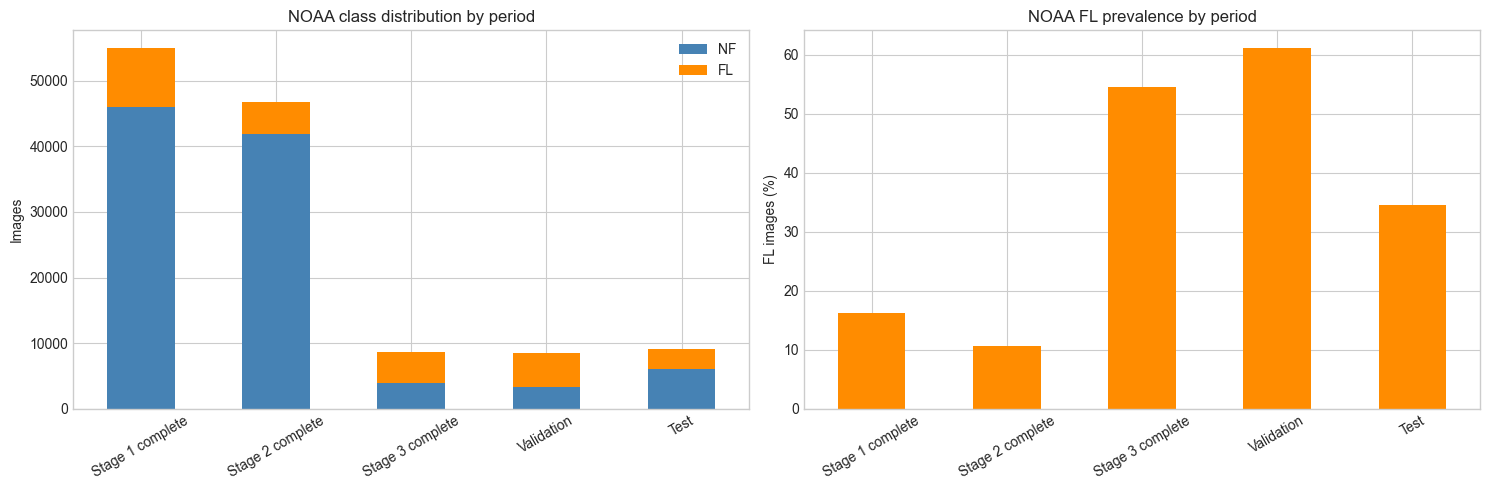

In [ ]:
plot_data = complete_summary.set_index("dataset")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_data[["NF", "FL"]].plot(
    kind="bar",
    stacked=True,
    color=["steelblue", "darkorange"],
    ax=axes[0],
)

axes[0].set_title("NOAA class distribution by period")
axes[0].set_xlabel("")
axes[0].set_ylabel("Images")
axes[0].tick_params(axis="x", rotation=30)

plot_data["FL_percent"].plot(
    kind="bar",
    color="darkorange",
    ax=axes[1],
)

axes[1].set_title("NOAA FL prevalence by period")
axes[1].set_xlabel("")
axes[1].set_ylabel("FL images (%)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [8]:
# This searches for holdouts between 5% and 15%. 
# Every training–holdout boundary must contain a complete 24-hour NF gap.
def find_holdout_candidates(
    stage_data,
    target_fraction=0.15,
    minimum_fraction=0.05,
    maximum_fraction=0.15,
    minimum_fl=200,
    minimum_nf=200,
):
    """Find chronological holdouts separated by a valid 24-hour NF gap."""

    stage_data = (
        stage_data.sort_values("timestamp")
        .reset_index(drop=True)
    )

    # Create a full hourly index so missing images can invalidate a gap.
    hourly_index = pd.date_range(
        stage_data["timestamp"].min(),
        stage_data["timestamp"].max(),
        freq="h",
    )

    hourly_labels = (
        stage_data.set_index("timestamp")["goes_class"]
        .reindex(hourly_index)
    )

    # A valid gap has 24 available images and zero FL labels.
    rolling_count = hourly_labels.rolling(24).count()
    rolling_fl = hourly_labels.rolling(24).sum()

    valid_gap_ends = hourly_labels.index[
        (rolling_count == 24) & (rolling_fl == 0)
    ]

    candidates = []

    for gap_end in valid_gap_ends:
        gap_start = gap_end - pd.Timedelta(hours=23)
        holdout_start = gap_end + pd.Timedelta(hours=1)

        training = stage_data[
            stage_data["timestamp"] < gap_start
        ]

        holdout = stage_data[
            stage_data["timestamp"] >= holdout_start
        ]

        if training.empty or holdout.empty:
            continue

        train_fl = int(training["goes_class"].sum())
        train_nf = len(training) - train_fl
        holdout_fl = int(holdout["goes_class"].sum())
        holdout_nf = len(holdout) - holdout_fl

        retained = len(training) + len(holdout)
        holdout_fraction = len(holdout) / retained

        # Require useful class representation and a 5%–15% holdout.
        if not minimum_fraction <= holdout_fraction <= maximum_fraction:
            continue
        if holdout_fl < minimum_fl or holdout_nf < minimum_nf:
            continue
        if train_fl < minimum_fl or train_nf < minimum_nf:
            continue

        train_fl_percent = 100 * train_fl / len(training)
        holdout_fl_percent = 100 * holdout_fl / len(holdout)

        candidates.append({
            "gap_start": gap_start,
            "gap_end": gap_end,
            "train_start": training["timestamp"].min(),
            "train_end": training["timestamp"].max(),
            "holdout_start": holdout["timestamp"].min(),
            "holdout_end": holdout["timestamp"].max(),
            "train_samples": len(training),
            "train_NF": train_nf,
            "train_FL": train_fl,
            "train_FL_percent": train_fl_percent,
            "holdout_samples": len(holdout),
            "holdout_NF": holdout_nf,
            "holdout_FL": holdout_fl,
            "holdout_FL_percent": holdout_fl_percent,
            "holdout_percent": 100 * holdout_fraction,
            "size_error": abs(
                100 * holdout_fraction - 100 * target_fraction
            ),
            "class_shift": abs(
                holdout_fl_percent - train_fl_percent
            ),
        })

    candidates = pd.DataFrame(candidates)

    if candidates.empty:
        raise ValueError(
            "No valid holdout satisfies the selected requirements."
        )

    # Prefer a holdout near 15%, then a smaller class-distribution shift.
    return candidates.sort_values(
        ["size_error", "class_shift", "gap_start"]
    ).reset_index(drop=True)

In [9]:
# Find candidates for all three stages
stage_sets = {
    "Stage 1": complete_blocks["Stage 1 complete"],
    "Stage 2": complete_blocks["Stage 2 complete"],
    "Stage 3": complete_blocks["Stage 3 complete"],
}

candidate_tables = {}

columns = [
    "gap_start",
    "gap_end",
    "train_samples",
    "train_NF",
    "train_FL",
    "train_FL_percent",
    "holdout_samples",
    "holdout_NF",
    "holdout_FL",
    "holdout_FL_percent",
    "holdout_percent",
    "class_shift",
]

for stage_name, stage_frame in stage_sets.items():
    candidates = find_holdout_candidates(stage_frame)
    candidate_tables[stage_name] = candidates

    print(f"\n{stage_name}: candidates closest to 15%")
    display(candidates[columns].head(10))


Stage 1: candidates closest to 15%


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift
0,2017-01-06 04:00:00,2017-01-07 03:00:00,46638,38015,8623,18.489215,8230,7900,330,4.009721,14.999635,14.479494
1,2017-01-06 05:00:00,2017-01-07 04:00:00,46639,38016,8623,18.488818,8229,7899,330,4.010208,14.997813,14.478611
2,2017-01-06 06:00:00,2017-01-07 05:00:00,46640,38017,8623,18.488422,8228,7898,330,4.010695,14.995990,14.477727
3,2017-01-06 07:00:00,2017-01-07 06:00:00,46641,38018,8623,18.488026,8227,7897,330,4.011183,14.994168,14.476843
4,2017-01-06 08:00:00,2017-01-07 07:00:00,46642,38019,8623,18.487629,8226,7896,330,4.011670,14.992345,14.475959
5,2017-01-06 09:00:00,2017-01-07 08:00:00,46643,38020,8623,18.487233,8225,7895,330,4.012158,14.990523,14.475075
6,2017-01-06 10:00:00,2017-01-07 09:00:00,46644,38021,8623,18.486836,8224,7894,330,4.012646,14.988700,14.474191
7,2017-01-06 11:00:00,2017-01-07 10:00:00,46645,38022,8623,18.486440,8223,7893,330,4.013134,14.986878,14.473306
8,2017-01-06 12:00:00,2017-01-07 11:00:00,46646,38023,8623,18.486044,8222,7892,330,4.013622,14.985055,14.472422
9,2017-01-06 13:00:00,2017-01-07 12:00:00,46647,38024,8623,18.485648,8221,7891,330,4.014110,14.983232,14.471537



Stage 2: candidates closest to 15%


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift
0,2022-09-06 00:00:00,2022-09-06 23:00:00,39760,37740,2020,5.080483,7016,4078,2938,41.875713,14.999145,36.795230
1,2022-09-06 01:00:00,2022-09-07 00:00:00,39761,37741,2020,5.080355,7015,4077,2938,41.881682,14.997007,36.801327
2,2022-09-06 02:00:00,2022-09-07 01:00:00,39762,37742,2020,5.080227,7014,4076,2938,41.887653,14.994869,36.807426
3,2022-09-06 03:00:00,2022-09-07 02:00:00,39763,37743,2020,5.080100,7013,4075,2938,41.893626,14.992731,36.813527
4,2022-09-06 04:00:00,2022-09-07 03:00:00,39764,37744,2020,5.079972,7012,4074,2938,41.899601,14.990593,36.819629
5,2022-09-06 05:00:00,2022-09-07 04:00:00,39765,37745,2020,5.079844,7011,4073,2938,41.905577,14.988456,36.825733
6,2022-09-06 06:00:00,2022-09-07 05:00:00,39766,37746,2020,5.079716,7010,4072,2938,41.911555,14.986318,36.831839
7,2022-09-06 07:00:00,2022-09-07 06:00:00,39767,37747,2020,5.079589,7009,4071,2938,41.917535,14.984180,36.837946
8,2022-09-06 08:00:00,2022-09-07 07:00:00,39768,37748,2020,5.079461,7008,4070,2938,41.923516,14.982042,36.844055
9,2022-09-06 09:00:00,2022-09-07 08:00:00,39769,37749,2020,5.079333,7007,4069,2938,41.929499,14.979904,36.850166



Stage 3: candidates closest to 15%


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift
0,2024-05-24 21:00:00,2024-05-25 20:00:00,7798,3696,4102,52.603232,826,203,623,75.423729,9.577922,22.820497
1,2024-05-24 22:00:00,2024-05-25 21:00:00,7799,3697,4102,52.596487,825,202,623,75.515152,9.566327,22.918665
2,2024-05-24 23:00:00,2024-05-25 22:00:00,7800,3698,4102,52.589744,824,201,623,75.606796,9.554731,23.017053
3,2024-05-25 00:00:00,2024-05-25 23:00:00,7801,3699,4102,52.583002,823,200,623,75.698663,9.543135,23.115661


In [10]:
# inspect candidates with the smallest class shift
for stage_name, candidates in candidate_tables.items():
    balanced = candidates.sort_values(
        ["class_shift", "size_error"]
    )

    print(f"\n{stage_name}: candidates with smallest class shift")
    display(balanced[columns].head(10))


Stage 1: candidates with smallest class shift


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift
3244,2017-07-01 16:00:00,2017-07-02 15:00:00,50759,42071,8688,17.116176,4109,3844,265,6.449258,7.488882,10.666919
3243,2017-07-01 15:00:00,2017-07-02 14:00:00,50758,42070,8688,17.116514,4110,3845,265,6.447689,7.490705,10.668825
3242,2017-07-01 14:00:00,2017-07-02 13:00:00,50757,42069,8688,17.116851,4111,3846,265,6.446120,7.492528,10.670731
3241,2017-07-01 13:00:00,2017-07-02 12:00:00,50756,42068,8688,17.117188,4112,3847,265,6.444553,7.494350,10.672636
3240,2017-07-01 12:00:00,2017-07-02 11:00:00,50755,42067,8688,17.117525,4113,3848,265,6.442986,7.496173,10.674540
3239,2017-07-01 11:00:00,2017-07-02 10:00:00,50754,42066,8688,17.117863,4114,3849,265,6.441420,7.497995,10.676443
3238,2017-07-01 10:00:00,2017-07-02 09:00:00,50753,42065,8688,17.118200,4115,3850,265,6.439854,7.499818,10.678346
3237,2017-07-01 09:00:00,2017-07-02 08:00:00,50752,42064,8688,17.118537,4116,3851,265,6.438290,7.501640,10.680248
3236,2017-07-01 08:00:00,2017-07-02 07:00:00,50751,42063,8688,17.118875,4117,3852,265,6.436726,7.503463,10.682149
3235,2017-07-01 07:00:00,2017-07-02 06:00:00,50750,42062,8688,17.119212,4118,3853,265,6.435163,7.505285,10.684049



Stage 2: candidates with smallest class shift


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift
270,2022-10-14 10:00:00,2022-10-15 09:00:00,40677,38226,2451,6.025518,6099,3592,2507,41.105099,13.038738,35.079581
271,2022-10-14 11:00:00,2022-10-15 10:00:00,40678,38227,2451,6.025370,6098,3591,2507,41.111840,13.036600,35.086470
272,2022-10-14 12:00:00,2022-10-15 11:00:00,40679,38228,2451,6.025222,6097,3590,2507,41.118583,13.034462,35.093361
273,2022-10-14 13:00:00,2022-10-15 12:00:00,40680,38229,2451,6.025074,6096,3589,2507,41.125328,13.032324,35.100254
274,2022-10-14 14:00:00,2022-10-15 13:00:00,40681,38230,2451,6.024926,6095,3588,2507,41.132075,13.030186,35.107150
275,2022-10-14 15:00:00,2022-10-15 14:00:00,40682,38231,2451,6.024778,6094,3587,2507,41.138825,13.028049,35.114048
276,2022-10-14 16:00:00,2022-10-15 15:00:00,40683,38232,2451,6.024629,6093,3586,2507,41.145577,13.025911,35.120947
277,2022-10-14 17:00:00,2022-10-15 16:00:00,40684,38233,2451,6.024481,6092,3585,2507,41.152331,13.023773,35.127850
278,2022-10-14 18:00:00,2022-10-15 17:00:00,40685,38234,2451,6.024333,6091,3584,2507,41.159087,13.021635,35.134754
279,2022-10-14 19:00:00,2022-10-15 18:00:00,40686,38235,2451,6.024185,6090,3583,2507,41.165846,13.019497,35.141660



Stage 3: candidates with smallest class shift


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift
0,2024-05-24 21:00:00,2024-05-25 20:00:00,7798,3696,4102,52.603232,826,203,623,75.423729,9.577922,22.820497
1,2024-05-24 22:00:00,2024-05-25 21:00:00,7799,3697,4102,52.596487,825,202,623,75.515152,9.566327,22.918665
2,2024-05-24 23:00:00,2024-05-25 22:00:00,7800,3698,4102,52.589744,824,201,623,75.606796,9.554731,23.017053
3,2024-05-25 00:00:00,2024-05-25 23:00:00,7801,3699,4102,52.583002,823,200,623,75.698663,9.543135,23.115661


In [11]:
# Check how FL examples are divided
for stage_name, candidates in candidate_tables.items():
    review = candidates.copy()

    review["holdout_share_of_stage_FL"] = (
        100
        * review["holdout_FL"]
        / (review["train_FL"] + review["holdout_FL"])
    )

    print(f"\n{stage_name}: FL allocation review")
    display(
        review[
            columns + ["holdout_share_of_stage_FL"]
        ].head(10)
    )


Stage 1: FL allocation review


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift,holdout_share_of_stage_FL
0,2017-01-06 04:00:00,2017-01-07 03:00:00,46638,38015,8623,18.489215,8230,7900,330,4.009721,14.999635,14.479494,3.685915
1,2017-01-06 05:00:00,2017-01-07 04:00:00,46639,38016,8623,18.488818,8229,7899,330,4.010208,14.997813,14.478611,3.685915
2,2017-01-06 06:00:00,2017-01-07 05:00:00,46640,38017,8623,18.488422,8228,7898,330,4.010695,14.995990,14.477727,3.685915
3,2017-01-06 07:00:00,2017-01-07 06:00:00,46641,38018,8623,18.488026,8227,7897,330,4.011183,14.994168,14.476843,3.685915
4,2017-01-06 08:00:00,2017-01-07 07:00:00,46642,38019,8623,18.487629,8226,7896,330,4.011670,14.992345,14.475959,3.685915
5,2017-01-06 09:00:00,2017-01-07 08:00:00,46643,38020,8623,18.487233,8225,7895,330,4.012158,14.990523,14.475075,3.685915
6,2017-01-06 10:00:00,2017-01-07 09:00:00,46644,38021,8623,18.486836,8224,7894,330,4.012646,14.988700,14.474191,3.685915
7,2017-01-06 11:00:00,2017-01-07 10:00:00,46645,38022,8623,18.486440,8223,7893,330,4.013134,14.986878,14.473306,3.685915
8,2017-01-06 12:00:00,2017-01-07 11:00:00,46646,38023,8623,18.486044,8222,7892,330,4.013622,14.985055,14.472422,3.685915
9,2017-01-06 13:00:00,2017-01-07 12:00:00,46647,38024,8623,18.485648,8221,7891,330,4.014110,14.983232,14.471537,3.685915



Stage 2: FL allocation review


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift,holdout_share_of_stage_FL
0,2022-09-06 00:00:00,2022-09-06 23:00:00,39760,37740,2020,5.080483,7016,4078,2938,41.875713,14.999145,36.795230,59.257765
1,2022-09-06 01:00:00,2022-09-07 00:00:00,39761,37741,2020,5.080355,7015,4077,2938,41.881682,14.997007,36.801327,59.257765
2,2022-09-06 02:00:00,2022-09-07 01:00:00,39762,37742,2020,5.080227,7014,4076,2938,41.887653,14.994869,36.807426,59.257765
3,2022-09-06 03:00:00,2022-09-07 02:00:00,39763,37743,2020,5.080100,7013,4075,2938,41.893626,14.992731,36.813527,59.257765
4,2022-09-06 04:00:00,2022-09-07 03:00:00,39764,37744,2020,5.079972,7012,4074,2938,41.899601,14.990593,36.819629,59.257765
5,2022-09-06 05:00:00,2022-09-07 04:00:00,39765,37745,2020,5.079844,7011,4073,2938,41.905577,14.988456,36.825733,59.257765
6,2022-09-06 06:00:00,2022-09-07 05:00:00,39766,37746,2020,5.079716,7010,4072,2938,41.911555,14.986318,36.831839,59.257765
7,2022-09-06 07:00:00,2022-09-07 06:00:00,39767,37747,2020,5.079589,7009,4071,2938,41.917535,14.984180,36.837946,59.257765
8,2022-09-06 08:00:00,2022-09-07 07:00:00,39768,37748,2020,5.079461,7008,4070,2938,41.923516,14.982042,36.844055,59.257765
9,2022-09-06 09:00:00,2022-09-07 08:00:00,39769,37749,2020,5.079333,7007,4069,2938,41.929499,14.979904,36.850166,59.257765



Stage 3: FL allocation review


,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift,holdout_share_of_stage_FL
0,2024-05-24 21:00:00,2024-05-25 20:00:00,7798,3696,4102,52.603232,826,203,623,75.423729,9.577922,22.820497,13.185185
1,2024-05-24 22:00:00,2024-05-25 21:00:00,7799,3697,4102,52.596487,825,202,623,75.515152,9.566327,22.918665,13.185185
2,2024-05-24 23:00:00,2024-05-25 22:00:00,7800,3698,4102,52.589744,824,201,623,75.606796,9.554731,23.017053,13.185185
3,2024-05-25 00:00:00,2024-05-25 23:00:00,7801,3699,4102,52.583002,823,200,623,75.698663,9.543135,23.115661,13.185185


In [12]:
# Preliminary automatic choices
selected_rows = {}

for stage_name, candidates in candidate_tables.items():
    # Avoid putting most of a stage's FL samples in its holdout.
    review = candidates.copy()

    review["holdout_share_of_stage_FL"] = (
        review["holdout_FL"]
        / (review["train_FL"] + review["holdout_FL"])
    )

    sensible = review[
        review["holdout_share_of_stage_FL"] < 0.50
    ].copy()

    if sensible.empty:
        raise ValueError(
            f"{stage_name} has no candidate preserving most FL samples "
            "for training."
        )

    selected_rows[stage_name] = sensible.iloc[0]

selected_table = pd.DataFrame(selected_rows).T
display(selected_table[columns])

,gap_start,gap_end,train_samples,train_NF,train_FL,train_FL_percent,holdout_samples,holdout_NF,holdout_FL,holdout_FL_percent,holdout_percent,class_shift
Stage 1,2017-01-06 04:00:00,2017-01-07 03:00:00,46638,38015,8623,18.489215,8230,7900,330,4.009721,14.999635,14.479494
Stage 2,2022-11-12 01:00:00,2022-11-13 00:00:00,41360,38844,2516,6.083172,5416,2974,2442,45.088626,11.578587,39.005454
Stage 3,2024-05-24 21:00:00,2024-05-25 20:00:00,7798,3696,4102,52.603232,826,203,623,75.423729,9.577922,22.820497


In [13]:
selected_splits = {}

for stage_name, stage_frame in stage_sets.items():
    selected = selected_rows[stage_name]

    gap_start = selected["gap_start"]
    gap_end = selected["gap_end"]

    training = stage_frame[
        stage_frame["timestamp"] < gap_start
    ].copy()

    gap = stage_frame[
        stage_frame["timestamp"].between(gap_start, gap_end)
    ].copy()

    holdout = stage_frame[
        stage_frame["timestamp"] > gap_end
    ].copy()

    selected_splits[stage_name] = {
        "training": training,
        "gap": gap,
        "holdout": holdout,
    }

print("Preliminary Stage 1–3 splits created in memory.")

Preliminary Stage 1–3 splits created in memory.


In [14]:
# Final summary of preliminary splits
summary_rows = []

for stage_name, split in selected_splits.items():
    for role in ["training", "gap", "holdout"]:
        frame = split[role]

        row = summarize_period(
            f"{stage_name} {role}",
            frame,
        )
        row["role"] = role
        summary_rows.append(row)

# Add validation and test periods.
for name in ["Validation", "Test"]:
    row = summarize_period(name, complete_blocks[name])
    row["role"] = name.lower()
    summary_rows.append(row)

split_summary = pd.DataFrame(summary_rows)

display(split_summary[
    [
        "dataset",
        "role",
        "start",
        "end",
        "samples",
        "NF",
        "FL",
        "NF_percent",
        "FL_percent",
    ]
])

,dataset,role,start,end,samples,NF,FL,NF_percent,FL_percent
0,Stage 1 training,training,2010-12-06 07:00:00,2017-01-06 03:00:00,46638,38015,8623,81.510785,18.489215
1,Stage 1 gap,gap,2017-01-06 04:00:00,2017-01-07 03:00:00,24,24,0,100.000000,0.000000
2,Stage 1 holdout,holdout,2017-01-07 04:00:00,2017-12-31 23:00:00,8230,7900,330,95.990279,4.009721
3,Stage 2 training,training,2018-01-02 00:00:00,2022-11-12 00:00:00,41360,38844,2516,93.916828,6.083172
4,Stage 2 gap,gap,2022-11-12 01:00:00,2022-11-13 00:00:00,24,24,0,100.000000,0.000000
5,Stage 2 holdout,holdout,2022-11-13 01:00:00,2023-06-29 22:00:00,5416,2974,2442,54.911374,45.088626
6,Stage 3 training,training,2023-07-01 00:00:00,2024-05-24 20:00:00,7798,3696,4102,47.396768,52.603232
7,Stage 3 gap,gap,2024-05-24 21:00:00,2024-05-25 20:00:00,24,24,0,100.000000,0.000000
8,Stage 3 holdout,holdout,2024-05-25 21:00:00,2024-06-29 10:00:00,826,203,623,24.576271,75.423729
9,Validation,validation,2024-07-01 00:00:00,2025-06-30 23:00:00,8480,3299,5181,38.903302,61.096698


In [15]:
# Verify every internal gap
for stage_name, split in selected_splits.items():
    gap = split["gap"]

    assert len(gap) == 24, f"{stage_name}: gap is not 24 images"
    assert gap["goes_class"].sum() == 0, (
        f"{stage_name}: gap contains FL labels"
    )

    expected = pd.date_range(
        gap["timestamp"].min(),
        gap["timestamp"].max(),
        freq="h",
    )

    assert len(expected.difference(gap["timestamp"])) == 0, (
        f"{stage_name}: gap contains missing hours"
    )

print("All internal training–holdout gaps are valid.")

All internal training–holdout gaps are valid.


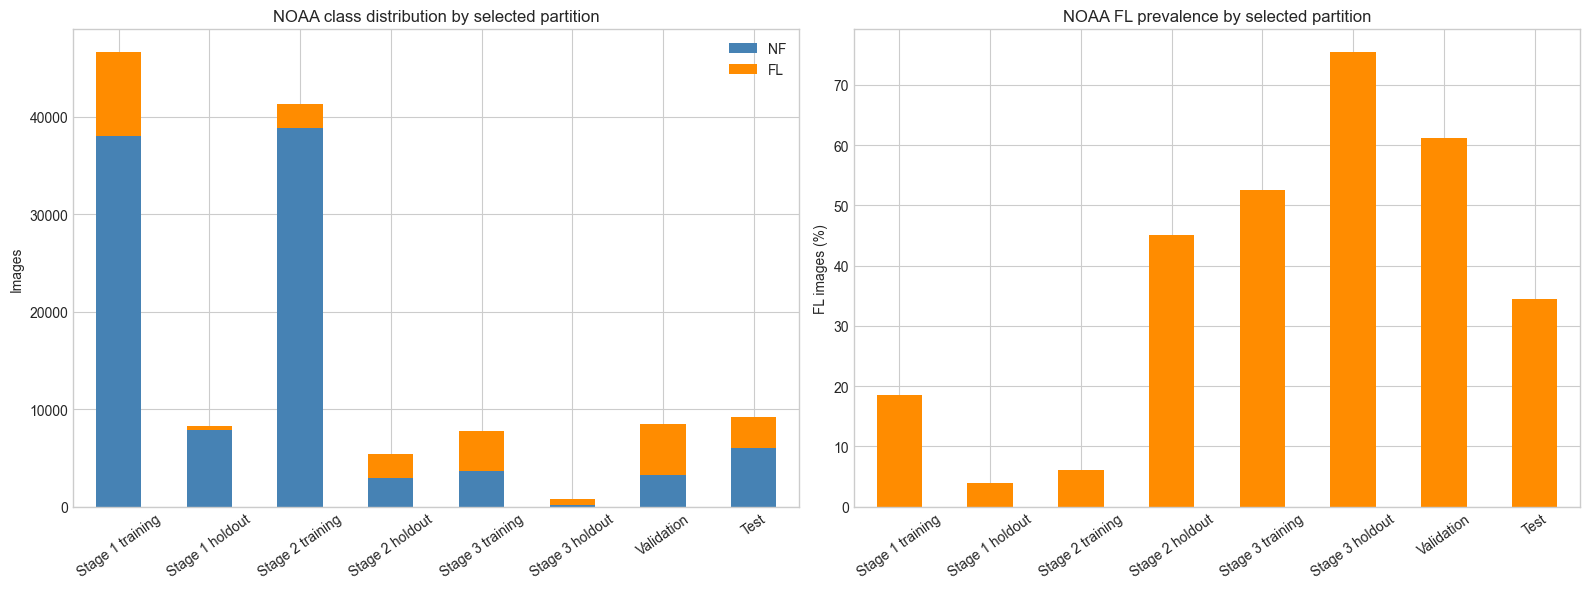

In [16]:
# Plot the selected distributions
plot_frame = (
    split_summary[
        split_summary["role"].isin(
            ["training", "holdout", "validation", "test"]
        )
    ]
    .set_index("dataset")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_frame[["NF", "FL"]].plot(
    kind="bar",
    stacked=True,
    color=["steelblue", "darkorange"],
    ax=axes[0],
)

axes[0].set_title("NOAA class distribution by selected partition")
axes[0].set_xlabel("")
axes[0].set_ylabel("Images")
axes[0].tick_params(axis="x", rotation=35)

plot_frame["FL_percent"].plot(
    kind="bar",
    color="darkorange",
    ax=axes[1],
)

axes[1].set_title("NOAA FL prevalence by selected partition")
axes[1].set_xlabel("")
axes[1].set_ylabel("FL images (%)")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()